In [1]:
import importlib
import sys

print("Python:", sys.version.split()[0])
print("Environment:", sys.executable)
print("-" * 50)

libraries = {
    "pandas": "pandas",
    "numpy": "numpy",
    "scikit-learn": "sklearn",
    "matplotlib": "matplotlib",
    "joblib": "joblib",
}

for name, module in libraries.items():
    try:
        lib = importlib.import_module(module)
        print(f"OK   {name}: {lib.__version__}")
    except Exception as error:
        print(f"FAIL {name}: {error}")

Python: 3.13.9
Environment: E:\anaconda3\python.exe
--------------------------------------------------
OK   pandas: 2.3.3
OK   numpy: 2.3.5
OK   scikit-learn: 1.7.2
OK   matplotlib: 3.10.6
OK   joblib: 1.5.2


In [1]:
from pathlib import Path
import pandas as pd

# CSV ရှိတဲ့နေရာနဲ့ မတူရင် ဒီ path ကို ပြင်ပါ
csv_path =Path("data/RR-28_EDA_Telemetry_data.csv")

if not csv_path.is_file():
    raise FileNotFoundError(f"CSV ဖိုင် မတွေ့ပါ: {csv_path}")

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nColumn types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

print("\nExact duplicate rows:", df.duplicated().sum())

display(df.head())

FileNotFoundError: CSV ဖိုင် မတွေ့ပါ: data\RR-28_EDA_Telemetry_data.csv

In [3]:
import numpy as np

features = [
    "Temp_degC_ISS",
    "RH_percent_ISS",
    "CO2_ppm_ISS",
]

# မူရင်း df ကို မပြောင်းဘဲ copy ယူပါ
data = df[["Controller_Time_GMT"] + features].copy()

data["timestamp"] = pd.to_datetime(
    data["Controller_Time_GMT"],
    format="%Y-%m-%d %H:%M",
    errors="coerce",
)

data = data.drop(columns="Controller_Time_GMT")

# Infinite values ရှိရင် missing အဖြစ် သတ်မှတ်ပါ
data[features] = data[features].replace(
    [np.inf, -np.inf], np.nan
)

print("Invalid timestamps:", data["timestamp"].isna().sum())

# Timestamp တူတဲ့ rows အားလုံး ပြပါ
duplicate_mask = data["timestamp"].duplicated(keep=False)
duplicate_mask &= data["timestamp"].notna()

print("\nRows with duplicate timestamps:", duplicate_mask.sum())
display(data.loc[duplicate_mask].sort_values("timestamp"))

# Missing values ပါတဲ့ rows ကို သီးခြားထားပါ
missing_mask = data[features].isna().any(axis=1)
missing_rows = data.loc[missing_mask].copy()

print("\nRows with missing ISS values:", len(missing_rows))
display(missing_rows)

# Complete rows ကိုသာ နောက်တစ်ဆင့်အတွက် ယူပါ
# Duplicate timestamps ကို ယခု မဖယ်သေးပါ
clean_data = (
    data.dropna(subset=["timestamp"] + features)
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# Unique timestamps ကြား အချိန်ကွာဟမှု စစ်ပါ
unique_times = (
    clean_data["timestamp"]
    .drop_duplicates()
    .reset_index(drop=True)
)

gaps = pd.DataFrame({
    "previous_time": unique_times.shift(1),
    "current_time": unique_times,
    "gap_minutes": unique_times.diff().dt.total_seconds() / 60,
})

print("\nTime gaps longer than 1 minute:")
display(gaps.loc[gaps["gap_minutes"] > 1])

print("\nComplete rows:", len(clean_data))
print("Start:", clean_data["timestamp"].min())
print("End:", clean_data["timestamp"].max())

display(clean_data[features].describe())

Invalid timestamps: 0

Rows with duplicate timestamps: 14


,Temp_degC_ISS,RH_percent_ISS,CO2_ppm_ISS,timestamp
5983,23.0,36.0,3831.0,2024-03-29
5984,23.0,36.0,4259.0,2024-03-29
8863,22.5,50.0,4752.0,2024-03-31
8864,22.5,50.0,3905.0,2024-03-31
24702,22.4,40.0,4002.0,2024-04-11
24703,22.4,40.0,3793.0,2024-04-11
34773,22.6,38.0,4227.0,2024-04-18
34774,22.6,38.0,4185.0,2024-04-18
40533,23.3,40.0,3862.0,2024-04-22
40534,23.3,40.0,3926.0,2024-04-22



Rows with missing ISS values: 2


,Temp_degC_ISS,RH_percent_ISS,CO2_ppm_ISS,timestamp
0,NaN,NaN,486.0,2024-03-21 00:00:00
61487,22.6,50.0,NaN,2024-05-06 13:16:00



Time gaps longer than 1 minute:


,previous_time,current_time,gap_minutes
223,2024-03-24 23:59:00,2024-03-25 00:01:00,2.0
7422,2024-03-29 23:59:00,2024-03-30 00:01:00,2.0
10301,2024-03-31 23:59:00,2024-04-01 00:01:00,2.0
23260,2024-04-09 23:59:00,2024-04-10 00:01:00,2.0
26139,2024-04-11 23:59:00,2024-04-12 00:01:00,2.0
30458,2024-04-14 23:59:00,2024-04-15 00:01:00,2.0
31128,2024-04-15 11:10:00,2024-04-15 11:12:00,2.0
31148,2024-04-15 11:31:00,2024-04-15 11:33:00,2.0
31169,2024-04-15 11:53:00,2024-04-15 11:55:00,2.0
31175,2024-04-15 12:00:00,2024-04-15 12:02:00,2.0



Complete rows: 61486
Start: 2024-03-24 20:17:00
End: 2024-05-06 13:15:00


,Temp_degC_ISS,RH_percent_ISS,CO2_ppm_ISS
count,61486.000000,61486.000000,61486.000000
mean,22.469136,38.828221,3709.891813
std,0.653145,4.048309,924.052148
min,17.700000,31.000000,451.000000
25%,22.200000,36.000000,3523.000000
50%,22.500000,38.000000,3892.000000
75%,22.800000,40.000000,4160.000000
max,26.900000,71.000000,8886.000000


In [5]:
import matplotlib.pyplot as plt

Train: 36,883 rows | 2024-03-24 20:17:00 → 2024-04-19 11:18:00
Validation: 12,294 rows | 2024-04-19 11:19:00 → 2024-04-28 00:16:00
Test: 12,295 rows | 2024-04-28 00:17:00 → 2024-05-06 13:15:00

Excluded conflicting rows: 14
Total modeling rows: 61472
Features: ['Temp_degC_ISS', 'RH_percent_ISS', 'CO2_ppm_ISS']


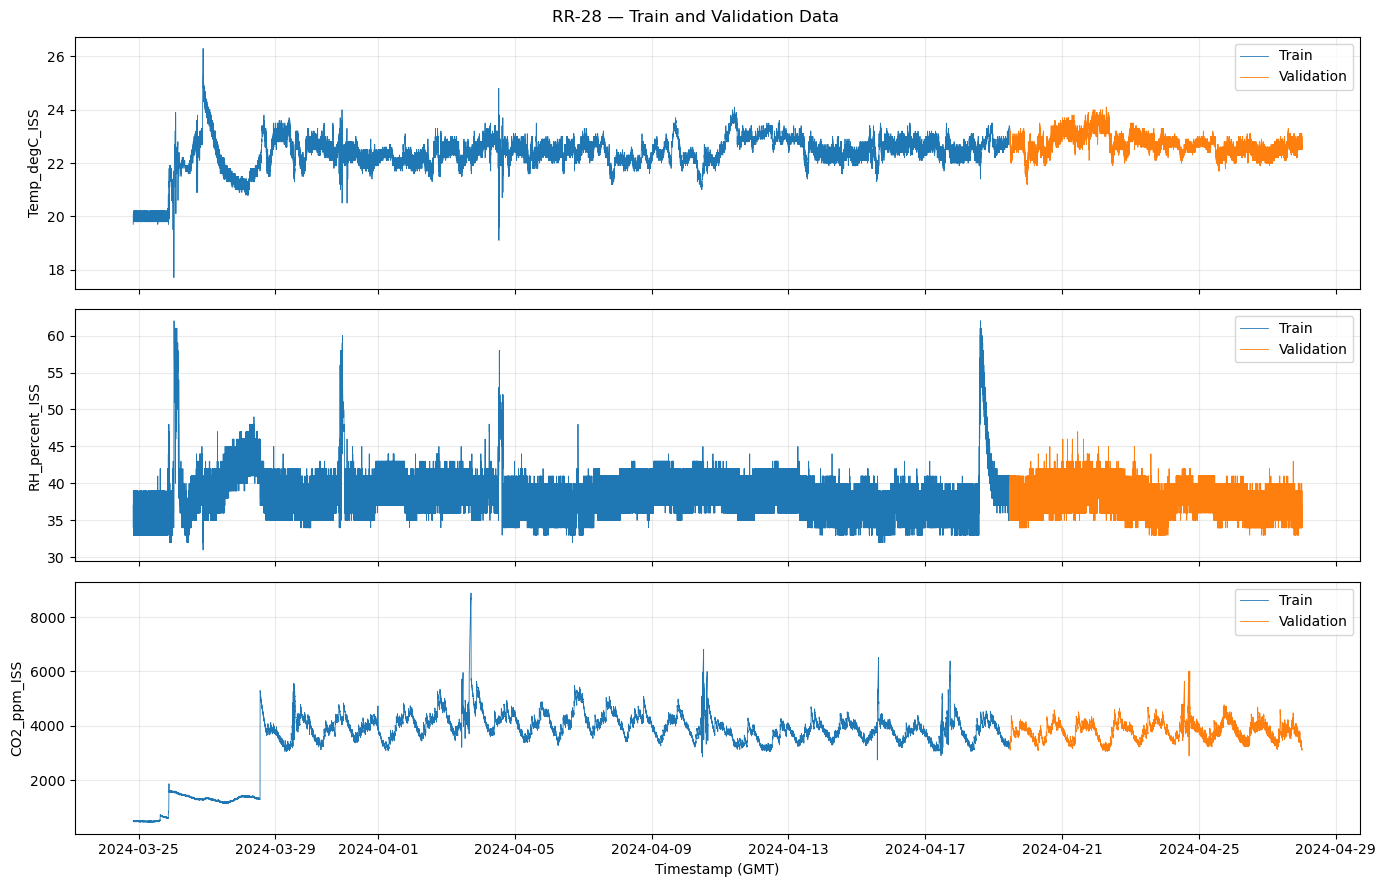

In [6]:
from pathlib import Path

output_dir = Path("training_outputs")
output_dir.mkdir(exist_ok=True)

# Conflicting timestamps ကို သီးခြားသိမ်းပါ
conflict_mask = clean_data["timestamp"].duplicated(keep=False)

conflicting_rows = clean_data.loc[conflict_mask].copy()
conflicting_rows.to_csv(
    output_dir / "excluded_duplicate_timestamps.csv",
    index=False,
)

missing_rows.to_csv(
    output_dir / "excluded_missing_values.csv",
    index=False,
)

# ပထမ baseline model အတွက် conflicting rows အားလုံး ဖယ်ထားပါ
model_data = (
    clean_data.loc[~conflict_mask]
    .sort_values("timestamp")
    .reset_index(drop=True)
)

assert model_data["timestamp"].is_unique
assert model_data[features].notna().all().all()

# Chronological split — shuffle မလုပ်ပါ
n = len(model_data)
train_end = int(n * 0.60)
val_end = int(n * 0.80)

train_df = model_data.iloc[:train_end].copy()
val_df = model_data.iloc[train_end:val_end].copy()
test_df = model_data.iloc[val_end:].copy()

X_train = train_df[features].copy()
X_val = val_df[features].copy()
X_test = test_df[features].copy()

for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(
        f"{name}: {len(part):,} rows | "
        f"{part['timestamp'].min()} → "
        f"{part['timestamp'].max()}"
    )

print("\nExcluded conflicting rows:", len(conflicting_rows))
print("Total modeling rows:", len(model_data))
print("Features:", features)

# Train / Validation ကိုကြည့်ပြီးမှ model ဆောက်ပါ
# Test ကို နောက်ဆုံး evaluation အတွက် ချန်ထားပါ
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

for ax, feature in zip(axes, features):
    ax.plot(
        train_df["timestamp"], train_df[feature],
        label="Train", linewidth=0.6,
    )
    ax.plot(
        val_df["timestamp"], val_df[feature],
        label="Validation", linewidth=0.6,
    )
    ax.set_ylabel(feature)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("Timestamp (GMT)")
fig.suptitle("RR-28 — Train and Validation Data")
plt.tight_layout()
plt.show()

Training completed.

Anomaly score percentiles:
Train: 50th=0.4184, 95th=0.6157, 99th=0.6577
Validation: 50th=0.4022, 95th=0.5000, 99th=0.5538

Top 10 most unusual validation observations:


,timestamp,Temp_degC_ISS,RH_percent_ISS,CO2_ppm_ISS,anomaly_score
40943,2024-04-22 07:00:00,24.1,43.0,3240.0,0.617931
41021,2024-04-22 08:18:00,23.9,43.0,3177.0,0.615803
41016,2024-04-22 08:13:00,23.8,43.0,3149.0,0.606876
40144,2024-04-21 17:40:00,23.7,44.0,3924.0,0.606112
40776,2024-04-22 04:13:00,24.0,42.0,3174.0,0.604130
41032,2024-04-22 08:29:00,23.6,45.0,3338.0,0.602859
40662,2024-04-22 02:19:00,23.9,43.0,3548.0,0.598362
40786,2024-04-22 04:23:00,23.9,42.0,3133.0,0.597890
39738,2024-04-21 10:54:00,23.3,47.0,3931.0,0.597640
40781,2024-04-22 04:18:00,23.9,42.0,3165.0,0.593775


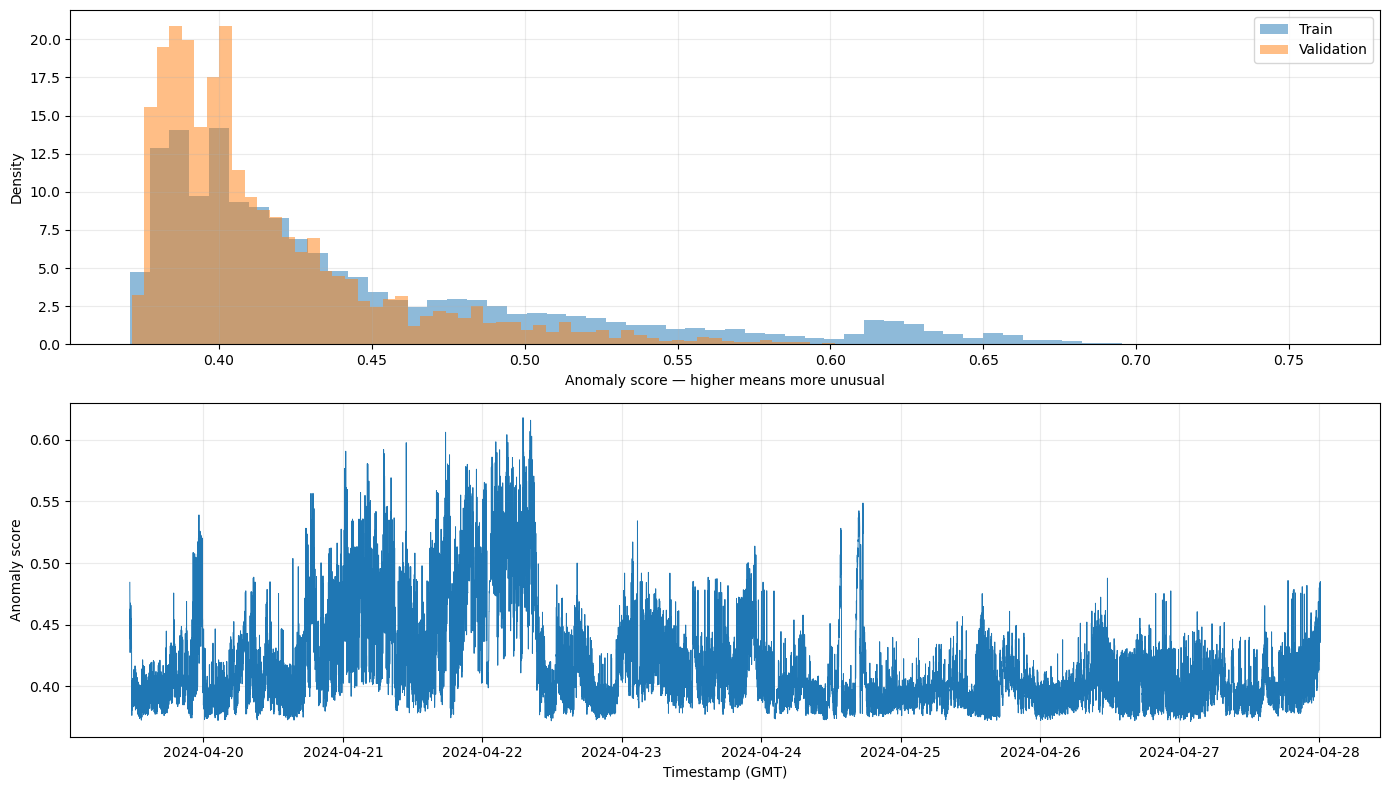

In [7]:
from sklearn.ensemble import IsolationForest
import numpy as np
import matplotlib.pyplot as plt

model = IsolationForest(
    n_estimators=100,
    max_samples="auto",
    contamination="auto",
    random_state=42,
    n_jobs=-1,
)

# Train data နဲ့သာ fit လုပ်ပါ
model.fit(X_train)

# Higher score = more unusual
train_scores = -model.score_samples(X_train)
val_scores = -model.score_samples(X_val)

print("Training completed.")
print("\nAnomaly score percentiles:")

for name, scores in [
    ("Train", train_scores),
    ("Validation", val_scores),
]:
    print(
        f"{name}: "
        f"50th={np.percentile(scores, 50):.4f}, "
        f"95th={np.percentile(scores, 95):.4f}, "
        f"99th={np.percentile(scores, 99):.4f}"
    )

# Validation results ကို သီးခြားထားပါ
val_results = val_df.copy()
val_results["anomaly_score"] = val_scores

print("\nTop 10 most unusual validation observations:")
display(
    val_results.nlargest(10, "anomaly_score")[
        ["timestamp"] + features + ["anomaly_score"]
    ]
)

# Score distributions
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].hist(
    train_scores, bins=60, alpha=0.5,
    density=True, label="Train"
)
axes[0].hist(
    val_scores, bins=60, alpha=0.5,
    density=True, label="Validation"
)
axes[0].set_xlabel("Anomaly score — higher means more unusual")
axes[0].set_ylabel("Density")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Validation score timeline
axes[1].plot(
    val_results["timestamp"],
    val_results["anomaly_score"],
    linewidth=0.7,
)
axes[1].set_xlabel("Timestamp (GMT)")
axes[1].set_ylabel("Anomaly score")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

,validation_percentile,threshold,flagged_observations,flagged_percent
0,95.0,0.499985,615,5.00
1,97.5,0.524905,308,2.51
2,99.0,0.553837,123,1.00
3,99.5,0.567634,62,0.50



Provisional threshold: 0.5538
Flagged observations: 123


,observed_rows,flagged_rows,flagged_percent
timestamp,,,
2024-04-19,761,0,0.00
2024-04-20,1440,2,0.14
2024-04-21,1440,44,3.06
2024-04-22,1439,77,5.35
2024-04-23,1439,0,0.00
2024-04-24,1438,0,0.00
2024-04-25,1440,0,0.00
2024-04-26,1440,0,0.00
2024-04-27,1440,0,0.00


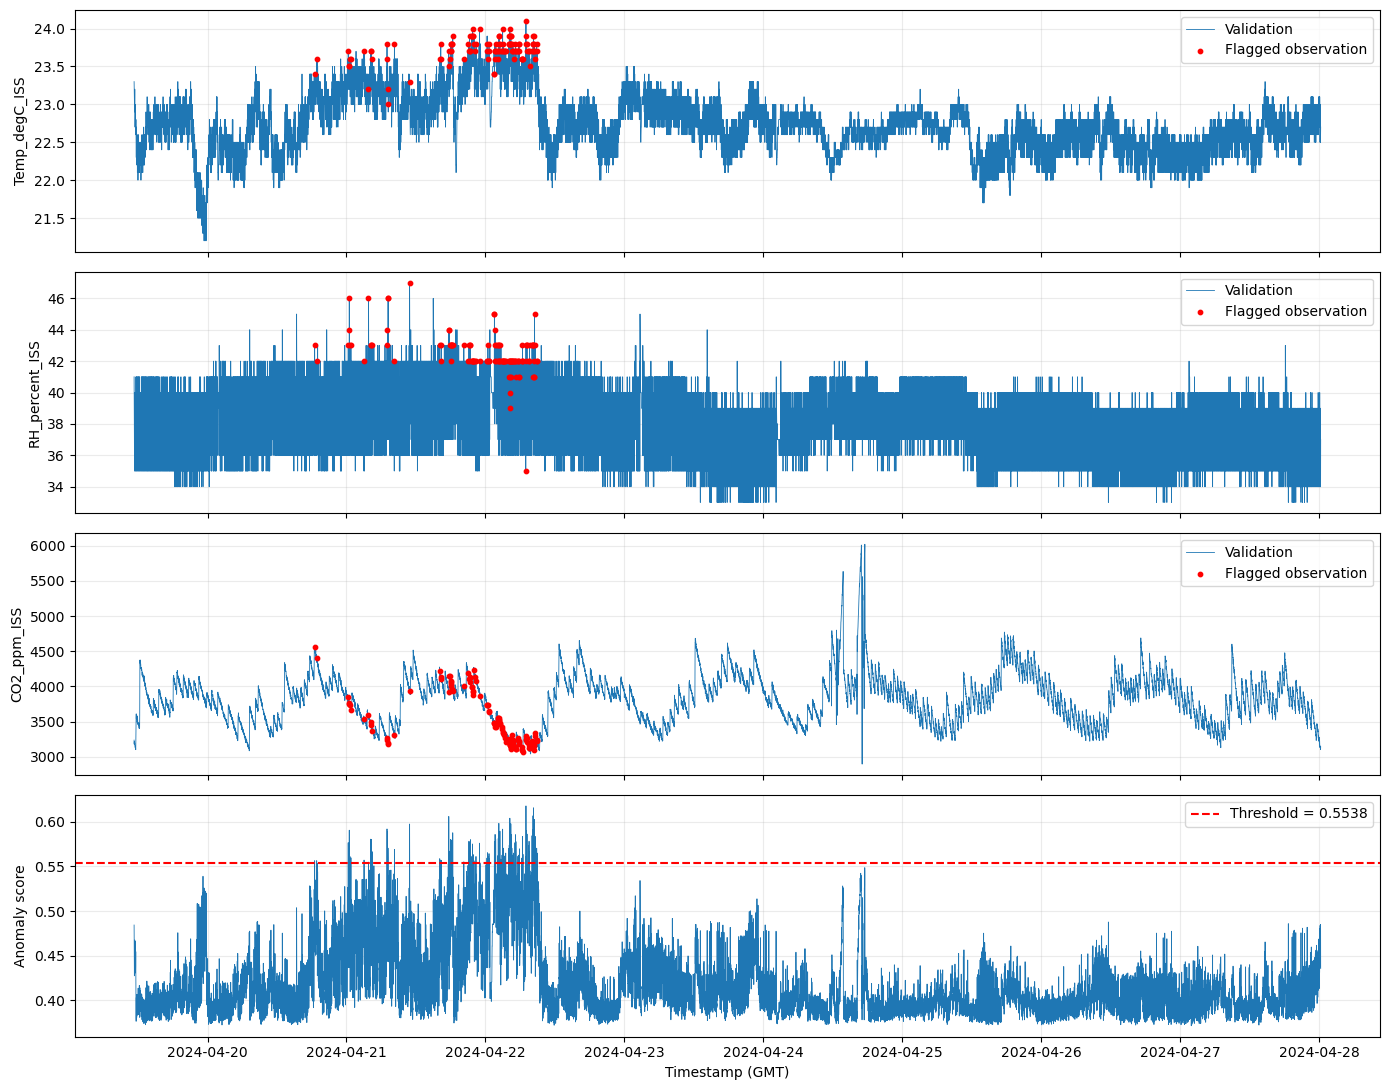

In [8]:
# Threshold candidates — clinical limits မဟုတ်ပါ
rows = []

for percentile in [95, 97.5, 99, 99.5]:
    candidate = float(np.percentile(val_scores, percentile))
    flagged = val_scores > candidate

    rows.append({
        "validation_percentile": percentile,
        "threshold": candidate,
        "flagged_observations": int(flagged.sum()),
        "flagged_percent": round(100 * flagged.mean(), 2),
    })

display(pd.DataFrame(rows))

# ပထမ prototype အတွက် ယာယီ threshold
# Validation observations ရဲ့ အထူးခြားဆုံး ~1% ကို flag လုပ်မယ်
threshold = float(np.percentile(val_scores, 99))

val_results["is_anomaly"] = (
    val_results["anomaly_score"] > threshold
)

print(f"\nProvisional threshold: {threshold:.4f}")
print("Flagged observations:", val_results["is_anomaly"].sum())

# တစ်ရက်ချင်း observation flag အရေအတွက်
daily_summary = (
    val_results
    .set_index("timestamp")
    .resample("D")
    .agg(
        observed_rows=("is_anomaly", "size"),
        flagged_rows=("is_anomaly", "sum"),
    )
)

daily_summary["flagged_percent"] = (
    100 * daily_summary["flagged_rows"]
    / daily_summary["observed_rows"].replace(0, np.nan)
).round(2)

display(daily_summary)

# Features ပေါ်မှာ flagged observations ပြပါ
flagged_rows = val_results.loc[val_results["is_anomaly"]]

fig, axes = plt.subplots(
    4, 1, figsize=(14, 11), sharex=True
)

for ax, feature in zip(axes[:3], features):
    ax.plot(
        val_results["timestamp"],
        val_results[feature],
        linewidth=0.6,
        label="Validation",
    )
    ax.scatter(
        flagged_rows["timestamp"],
        flagged_rows[feature],
        color="red",
        s=10,
        label="Flagged observation",
        zorder=3,
    )
    ax.set_ylabel(feature)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.25)

axes[3].plot(
    val_results["timestamp"],
    val_results["anomaly_score"],
    linewidth=0.6,
)
axes[3].axhline(
    threshold,
    color="red",
    linestyle="--",
    label=f"Threshold = {threshold:.4f}",
)
axes[3].set_ylabel("Anomaly score")
axes[3].set_xlabel("Timestamp (GMT)")
axes[3].legend()
axes[3].grid(alpha=0.25)

plt.tight_layout()
plt.show()

Frozen threshold: 0.553837
Test observations: 12,295
Flagged observations: 2,018
Flagged percentage: 16.41%


,observed_rows,flagged_rows,flagged_percent
timestamp,,,
2024-04-28,1423,0,0.00
2024-04-29,1440,0,0.00
2024-04-30,1439,0,0.00
2024-05-01,1439,24,1.67
2024-05-02,1440,0,0.00
2024-05-03,1440,140,9.72
2024-05-04,1439,2,0.14
2024-05-05,1440,1057,73.40
2024-05-06,795,795,100.00



Top 10 unusual test observations:


,timestamp,Temp_degC_ISS,RH_percent_ISS,CO2_ppm_ISS,anomaly_score
59808,2024-05-05 09:31:00,26.3,61.0,4216.0,0.759397
59815,2024-05-05 09:38:00,25.5,66.0,4221.0,0.759397
59816,2024-05-05 09:39:00,25.3,63.0,4216.0,0.759397
59814,2024-05-05 09:37:00,25.4,67.0,4213.0,0.758370
59812,2024-05-05 09:35:00,25.2,63.0,4211.0,0.757857
59807,2024-05-05 09:30:00,26.5,64.0,4177.0,0.757345
59813,2024-05-05 09:36:00,25.4,66.0,4178.0,0.757345
59822,2024-05-05 09:45:00,24.9,67.0,4173.0,0.757345
59823,2024-05-05 09:46:00,25.0,67.0,4163.0,0.757345
59826,2024-05-05 09:49:00,25.3,67.0,4167.0,0.757345


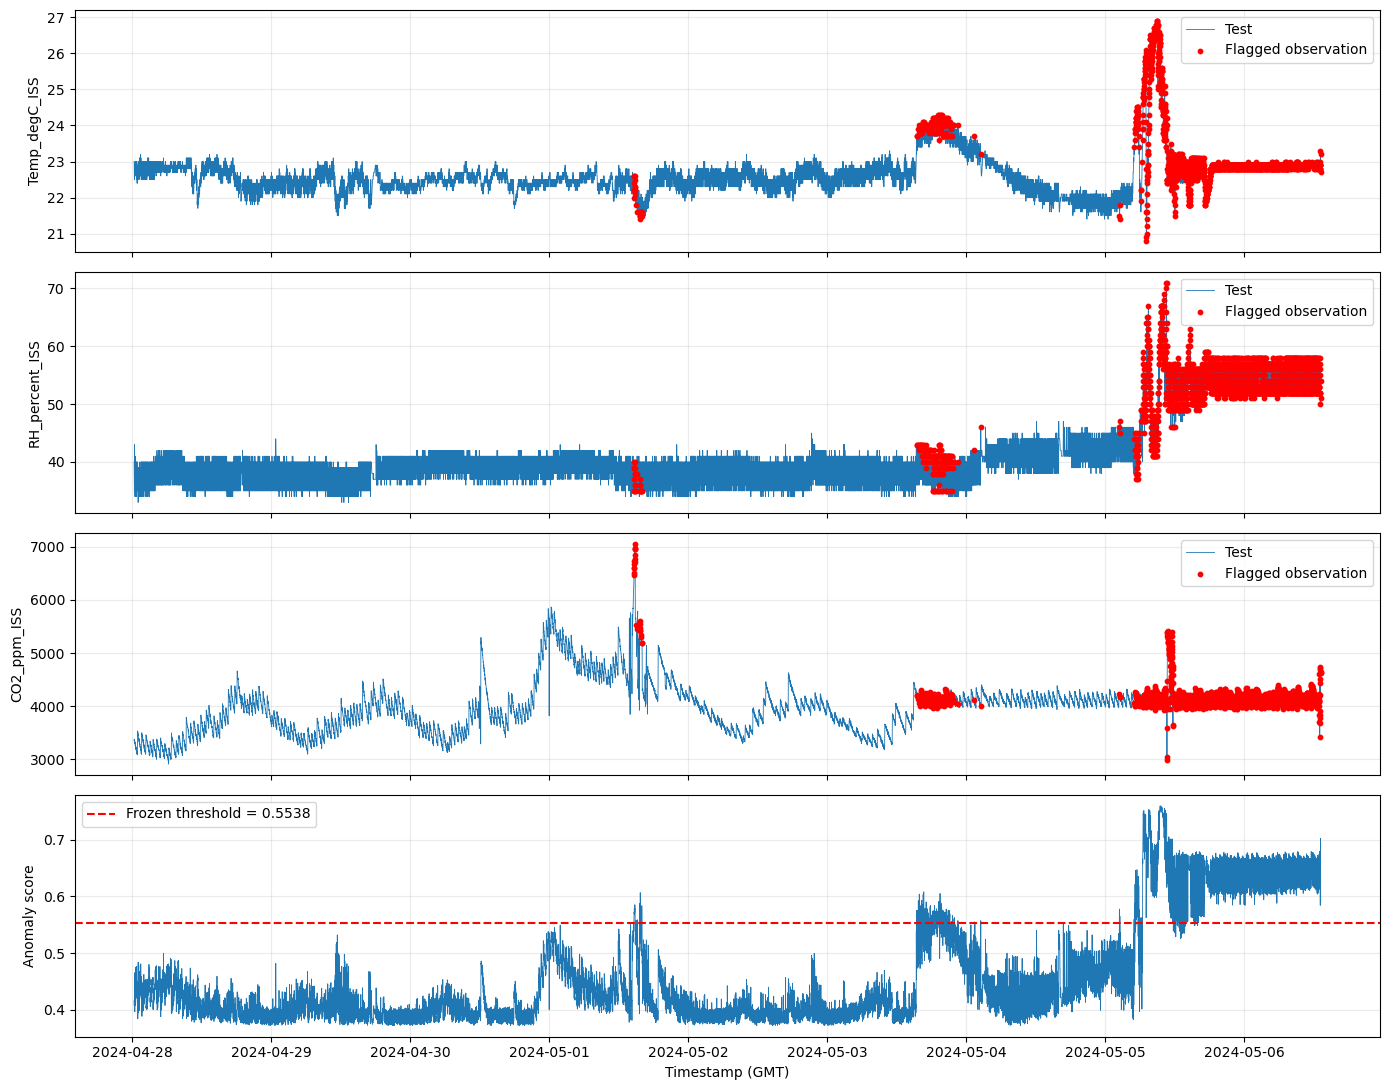

In [9]:
# Validation မှာ ရွေးထားတဲ့ threshold ကိုပဲ သုံးပါ
# Test data ကနေ threshold အသစ် မတွက်ပါနဲ့
frozen_threshold = float(threshold)

test_results = test_df.copy()
test_results["anomaly_score"] = -model.score_samples(X_test)
test_results["is_anomaly"] = (
    test_results["anomaly_score"] > frozen_threshold
)

print(f"Frozen threshold: {frozen_threshold:.6f}")
print(f"Test observations: {len(test_results):,}")
print(f"Flagged observations: {test_results['is_anomaly'].sum():,}")
print(
    f"Flagged percentage: "
    f"{100 * test_results['is_anomaly'].mean():.2f}%"
)

# နေ့အလိုက် flag အရေအတွက်
test_daily = (
    test_results.set_index("timestamp")
    .resample("D")
    .agg(
        observed_rows=("is_anomaly", "size"),
        flagged_rows=("is_anomaly", "sum"),
    )
)

test_daily["flagged_percent"] = (
    100 * test_daily["flagged_rows"]
    / test_daily["observed_rows"].replace(0, np.nan)
).round(2)

display(test_daily)

print("\nTop 10 unusual test observations:")
display(
    test_results.nlargest(10, "anomaly_score")[
        ["timestamp"] + features + ["anomaly_score"]
    ]
)

# Test graphs
flagged = test_results.loc[test_results["is_anomaly"]]

fig, axes = plt.subplots(
    4, 1, figsize=(14, 11), sharex=True
)

for ax, feature in zip(axes[:3], features):
    ax.plot(
        test_results["timestamp"],
        test_results[feature],
        linewidth=0.6,
        label="Test",
    )
    ax.scatter(
        flagged["timestamp"],
        flagged[feature],
        color="red",
        s=10,
        label="Flagged observation",
        zorder=3,
    )
    ax.set_ylabel(feature)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.25)

axes[3].plot(
    test_results["timestamp"],
    test_results["anomaly_score"],
    linewidth=0.6,
)
axes[3].axhline(
    frozen_threshold,
    color="red",
    linestyle="--",
    label=f"Frozen threshold = {frozen_threshold:.4f}",
)
axes[3].set_ylabel("Anomaly score")
axes[3].set_xlabel("Timestamp (GMT)")
axes[3].legend()
axes[3].grid(alpha=0.25)

plt.tight_layout()
plt.show()

# Evaluation results ကိုသာ သိမ်းပါ
test_results.to_csv(
    output_dir / "test_observation_results.csv",
    index=False,
)
test_daily.to_csv(
    output_dir / "test_daily_summary.csv"
)

In [10]:
def group_flagged_events(results):
    r = results.sort_values("timestamp").reset_index(drop=True).copy()

    flagged = r["is_anomaly"].astype(bool)
    previous_flagged = flagged.shift(1, fill_value=False)

    # Normal observation ပါလာရင် သို့မဟုတ် time gap ရှိရင်
    # event အသစ်အဖြစ် ခွဲပါ
    consecutive_time = (
        r["timestamp"].diff() == pd.Timedelta(minutes=1)
    )

    event_start = flagged & (
        ~previous_flagged | ~consecutive_time
    )

    r["event_id"] = event_start.cumsum()
    selected = r.loc[flagged].copy()

    events = (
        selected.groupby("event_id")
        .agg(
            start=("timestamp", "min"),
            end=("timestamp", "max"),
            flagged_observations=("timestamp", "size"),
            peak_score=("anomaly_score", "max"),
            temp_min=("Temp_degC_ISS", "min"),
            temp_max=("Temp_degC_ISS", "max"),
            rh_min=("RH_percent_ISS", "min"),
            rh_max=("RH_percent_ISS", "max"),
            co2_min=("CO2_ppm_ISS", "min"),
            co2_max=("CO2_ppm_ISS", "max"),
        )
        .reset_index()
    )

    events["elapsed_minutes"] = (
        events["end"] - events["start"]
    ).dt.total_seconds() / 60

    return events


test_events = group_flagged_events(test_results)

print("Flagged observations:", test_results["is_anomaly"].sum())
print("Consecutive flag events:", len(test_events))

print("\nLongest events:")
display(
    test_events.sort_values(
        "flagged_observations", ascending=False
    ).head(15)
)

test_events.to_csv(
    output_dir / "test_flagged_events.csv",
    index=False,
)

Flagged observations: 2018
Consecutive flag events: 128

Longest events:


,event_id,start,end,flagged_observations,peak_score,temp_min,temp_max,rh_min,rh_max,co2_min,co2_max,elapsed_minutes
127,128,2024-05-06 00:01:00,2024-05-06 13:15:00,795,0.702293,22.7,23.3,50.0,58.0,3413.0,4746.0,794.0
126,127,2024-05-05 16:06:00,2024-05-05 23:59:00,474,0.678653,21.8,23.1,49.0,59.0,3942.0,4331.0,473.0
99,100,2024-05-05 06:29:00,2024-05-05 11:47:00,319,0.759397,20.8,26.9,41.0,71.0,2980.0,5411.0,318.0
120,121,2024-05-05 13:55:00,2024-05-05 15:25:00,91,0.675904,21.8,23.1,49.0,63.0,3942.0,4218.0,90.0
92,93,2024-05-05 05:20:00,2024-05-05 05:42:00,23,0.646961,24.0,24.5,37.0,44.0,4106.0,4234.0,22.0
124,125,2024-05-05 15:42:00,2024-05-05 15:59:00,18,0.678653,22.5,23.1,49.0,56.0,4115.0,4288.0,17.0
106,107,2024-05-05 12:33:00,2024-05-05 12:46:00,14,0.675897,22.6,23.2,49.0,58.0,3987.0,4130.0,13.0
104,105,2024-05-05 12:14:00,2024-05-05 12:27:00,14,0.676361,22.5,23.1,49.0,56.0,3956.0,4227.0,13.0
0,1,2024-05-01 14:38:00,2024-05-01 14:50:00,13,0.585272,22.0,22.6,35.0,40.0,6474.0,7049.0,12.0
100,101,2024-05-05 11:49:00,2024-05-05 11:56:00,8,0.670787,21.9,23.1,49.0,56.0,4138.0,4240.0,7.0


In [11]:
# Validation မှ ဆက်တိုက် 120 မိနစ်ကို test fixture အဖြစ် ယူပါ
base = val_df.iloc[:120].reset_index(drop=True).copy()

assert len(base) == 120
assert (
    base["timestamp"].diff().iloc[1:]
    == pd.Timedelta(minutes=1)
).all(), "ဒီ segment မှာ time gap ရှိပါတယ်။"

# အလယ်က 60 observations ကိုပဲ ပြောင်းပါမယ်
start, stop = 30, 90

scenarios = {}

# 1. CO2 တက်ခြင်း
s = base.copy()
s.loc[start:stop - 1, "CO2_ppm_ISS"] += 3000
scenarios["CO2_step_plus_3000ppm"] = s

# 2. Temperature တဖြည်းဖြည်း တက်ခြင်း
s = base.copy()
s.loc[start:stop - 1, "Temp_degC_ISS"] += np.linspace(
    0, 4, stop - start
)
scenarios["Temperature_ramp_plus_4C"] = s

# 3. Humidity တက်ခြင်း
s = base.copy()
s.loc[start:stop - 1, "RH_percent_ISS"] += 20
scenarios["Humidity_step_plus_20points"] = s

# 4. Temperature နဲ့ Humidity နှစ်ခုလုံး တက်ခြင်း
s = base.copy()
s.loc[start:stop - 1, "Temp_degC_ISS"] += 4
s.loc[start:stop - 1, "RH_percent_ISS"] += 20
scenarios["Combined_temperature_humidity"] = s

# မပြောင်းထားတဲ့ segment ကိုလည်း တူညီတဲ့ model နဲ့ score တွက်ပါ
base_scores = -model.score_samples(base[features])
base_flags = base_scores > frozen_threshold

summary = []
synthetic_results = []

for name, scenario in scenarios.items():
    scores = -model.score_samples(scenario[features])
    flags = scores > frozen_threshold

    injected_flags = flags[start:stop]
    detected_positions = np.flatnonzero(injected_flags)

    # Injection စပြီး ပထမဆုံး flag ရတဲ့အချိန်အထိ
    delay = (
        int(detected_positions[0])
        if len(detected_positions)
        else np.nan
    )

    summary.append({
        "scenario": name,
        "modified_observations": stop - start,
        "flags_in_modified_window": int(injected_flags.sum()),
        "modified_window_flag_percent":
            round(100 * injected_flags.mean(), 2),
        "first_flag_delay_minutes": delay,
        "same_window_flags_before_modification":
            int(base_flags[start:stop].sum()),
    })

    result = scenario.copy()
    result["scenario"] = name
    result["is_synthetic"] = True
    result["is_modified"] = False
    result.loc[start:stop - 1, "is_modified"] = True
    result["anomaly_score"] = scores
    result["is_anomaly"] = flags
    synthetic_results.append(result)

summary_df = pd.DataFrame(summary)
display(summary_df)

summary_df.to_csv(
    output_dir / "synthetic_scenario_summary.csv",
    index=False,
)

pd.concat(synthetic_results, ignore_index=True).to_csv(
    output_dir / "synthetic_scenario_observations.csv",
    index=False,
)

print("Synthetic tests completed. Model unchanged.")

,scenario,modified_observations,flags_in_modified_window,modified_window_flag_percent,first_flag_delay_minutes,same_window_flags_before_modification
0,CO2_step_plus_3000ppm,60,59,98.33,0,0
1,Temperature_ramp_plus_4C,60,36,60.00,24,0
2,Humidity_step_plus_20points,60,60,100.00,0,0
3,Combined_temperature_humidity,60,60,100.00,0,0


Synthetic tests completed. Model unchanged.


In [12]:
import joblib
import sklearn
from datetime import datetime, timezone

model_bundle = {
    "model": model,
    "model_version": "environment-iforest-v0.1",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),

    "features": features,
    "units": {
        "Temp_degC_ISS": "degC",
        "RH_percent_ISS": "percent",
        "CO2_ppm_ISS": "ppm",
    },

    "threshold": frozen_threshold,
    "score_definition": "-model.score_samples(X)",
    "flag_rule": "anomaly_score > threshold",
    "threshold_method": "99th percentile of validation scores",

    "preprocessing": {
        "scaling": None,
        "missing_values": "Reject incomplete observations",
        "conflicting_timestamps":
            "All conflicting rows excluded from baseline training",
        "interpolation": None,
    },

    "training_source": "RR-28_EDA_Telemetry_data.csv",
    "train_start": train_df["timestamp"].min().isoformat(),
    "train_end": train_df["timestamp"].max().isoformat(),
    "validation_start": val_df["timestamp"].min().isoformat(),
    "validation_end": val_df["timestamp"].max().isoformat(),
    "train_rows": len(train_df),

    "sklearn_version": sklearn.__version__,
    "purpose": "Environmental anomaly screening",
    "limitations": [
        "Not a disease prediction model",
        "Anomaly score is not a probability",
        "Not a replacement for independently reviewed safety limits",
        "Clinical performance has not been validated",
    ],
}

model_path = output_dir / "environment_iforest_v01.joblib"
joblib.dump(model_bundle, model_path)

# ပြန်ဖွင့်ပြီး scores တူညီကြောင်း စစ်ပါ
loaded_bundle = joblib.load(model_path)

original_scores = -model.score_samples(X_val.iloc[:100])
loaded_scores = -loaded_bundle["model"].score_samples(
    X_val.iloc[:100][loaded_bundle["features"]]
)

np.testing.assert_allclose(
    original_scores,
    loaded_scores,
    rtol=0,
    atol=1e-12,
)

print("Saved:", model_path.resolve())
print("Reload verification: PASSED")
print("Threshold:", loaded_bundle["threshold"])

Saved: E:\Nasa space App\training_outputs\environment_iforest_v01.joblib
Reload verification: PASSED
Threshold: 0.5538365329807832


In [13]:
from pathlib import Path
import pandas as pd
import numpy as np

downloads = Path(r"C:\Users\Asus Vivobook\Downloads")
cross_dir = output_dir / "cross_mission"
cross_dir.mkdir(parents=True, exist_ok=True)

mission_files = {
    "RR-20": downloads / "RR-20_EDA_Telemetry_data.csv",
    "RR-23": downloads / "RR-23_EDA_Telemetry_data.csv",
    "RR-25": downloads / "RR-25_EDA_Telemetry_data.csv",
}

cross_results = {}
summary_rows = []

for mission, path in mission_files.items():
    raw = pd.read_csv(path)

    required = ["Controller_Time_GMT"] + features
    missing_columns = set(required) - set(raw.columns)

    if missing_columns:
        raise ValueError(f"{mission}: missing columns {missing_columns}")

    d = raw[required].copy()

    d["timestamp"] = pd.to_datetime(
        d["Controller_Time_GMT"], errors="coerce"
    )

    for feature in features:
        d[feature] = pd.to_numeric(d[feature], errors="coerce")

    d[features] = d[features].replace(
        [np.inf, -np.inf], np.nan
    )

    invalid_time = d["timestamp"].isna()
    incomplete = d[features].isna().any(axis=1)
    duplicates = (
        d["timestamp"].notna()
        & d["timestamp"].duplicated(keep=False)
    )

    excluded = invalid_time | incomplete | duplicates

    # Exclusion reasons ကို ထိန်းသိမ်းပါ
    d["invalid_timestamp"] = invalid_time
    d["incomplete_features"] = incomplete
    d["duplicate_timestamp"] = duplicates

    d.loc[excluded].to_csv(
        cross_dir / f"{mission}_excluded_rows.csv",
        index=False,
    )

    scored = (
        d.loc[~excluded, ["timestamp"] + features]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    if scored.empty:
        print(f"{mission}: No usable observations.")
        continue

    # Existing model + frozen threshold ကိုသာ သုံးပါ
    scored["anomaly_score"] = -model.score_samples(
        scored[features]
    )
    scored["is_anomaly"] = (
        scored["anomaly_score"] > frozen_threshold
    )

    cross_results[mission] = scored

    scored.to_csv(
        cross_dir / f"{mission}_scored.csv",
        index=False,
    )

    summary_rows.append({
        "mission": mission,
        "raw_rows": len(raw),
        "excluded_rows": int(excluded.sum()),
        "scored_rows": len(scored),
        "flagged_rows": int(scored["is_anomaly"].sum()),
        "flagged_percent":
            round(100 * scored["is_anomaly"].mean(), 2),
        "scored_start": scored["timestamp"].min(),
        "scored_end": scored["timestamp"].max(),
    })

cross_summary = pd.DataFrame(summary_rows)
display(cross_summary)

cross_summary.to_csv(
    cross_dir / "cross_mission_summary.csv",
    index=False,
)

print("Frozen threshold:", frozen_threshold)
print("Saved to:", cross_dir.resolve())
print("Model was not retrained.")

,mission,raw_rows,excluded_rows,scored_rows,flagged_rows,flagged_percent,scored_start,scored_end
0,RR-20,67976,13365,54611,2193,4.02,2023-11-21 17:40:00,2024-01-03 07:11:00
1,RR-23,52600,9676,42924,3636,8.47,2020-12-09 11:00:00,2021-01-08 16:50:00
2,RR-25,93763,137,93626,9693,10.35,2022-11-29 09:15:00,2023-02-02 11:57:00


Frozen threshold: 0.5538365329807832
Saved to: E:\Nasa space App\training_outputs\cross_mission
Model was not retrained.


C:\Users\Asus Vivobook\AppData\Local\Temp\ipykernel_39652\547422363.py:58: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


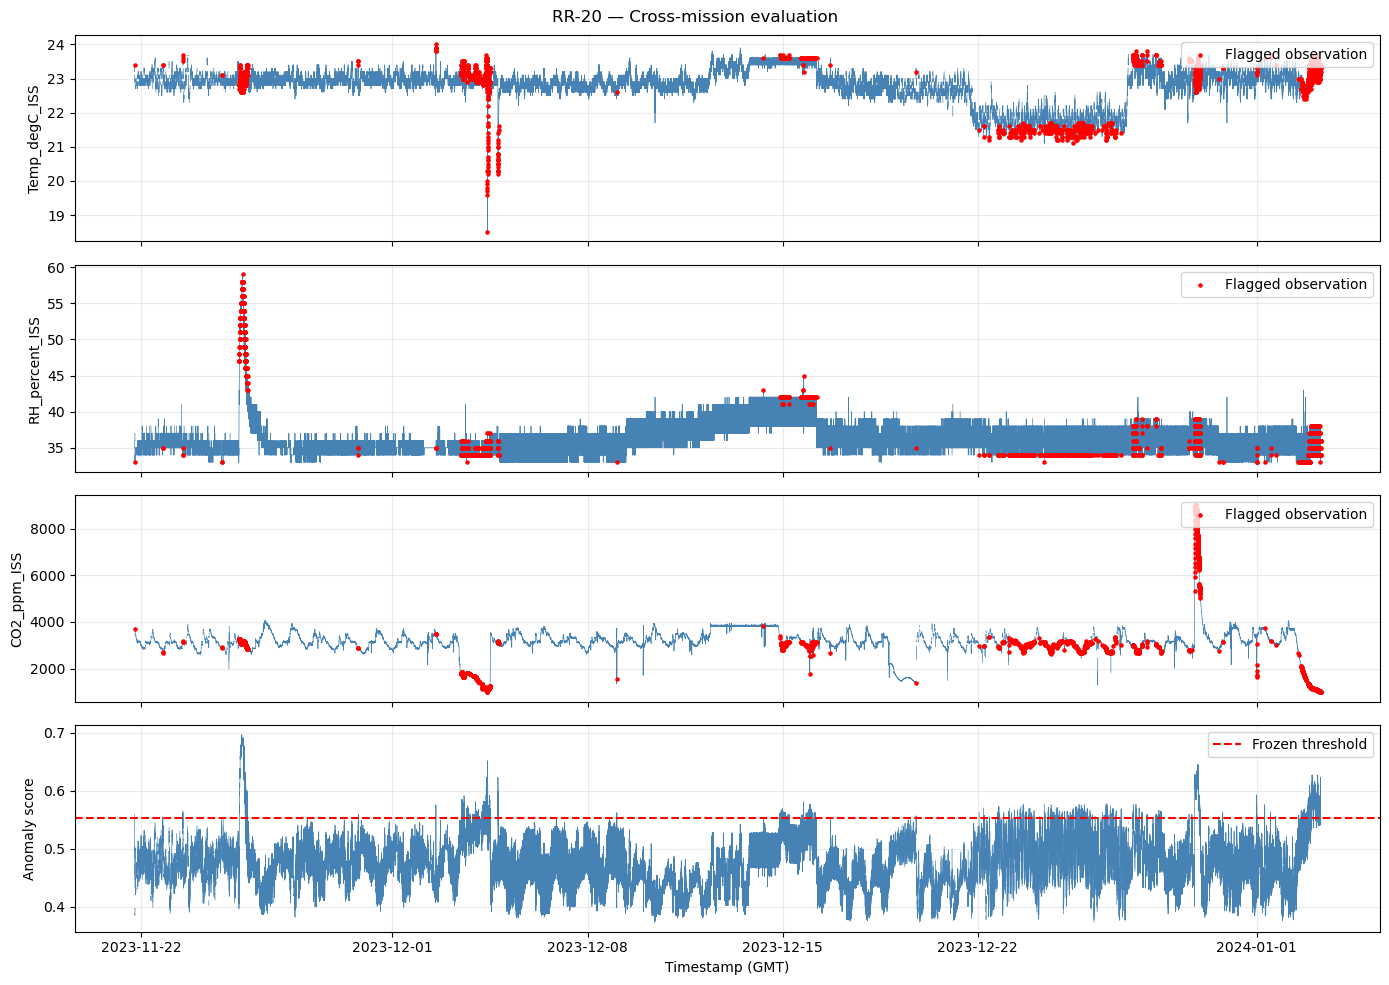

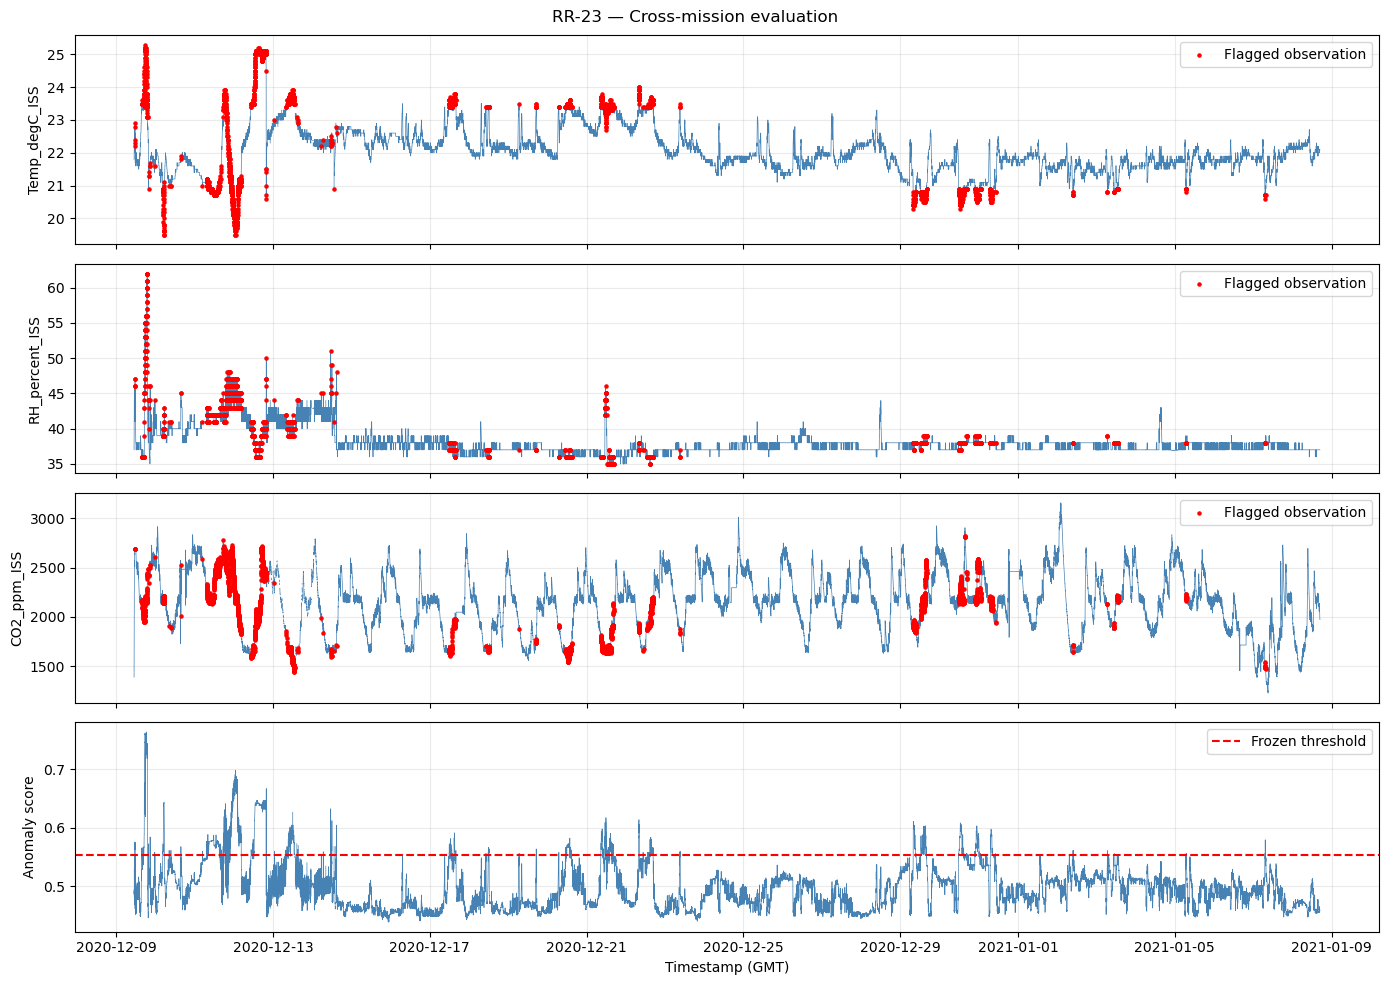

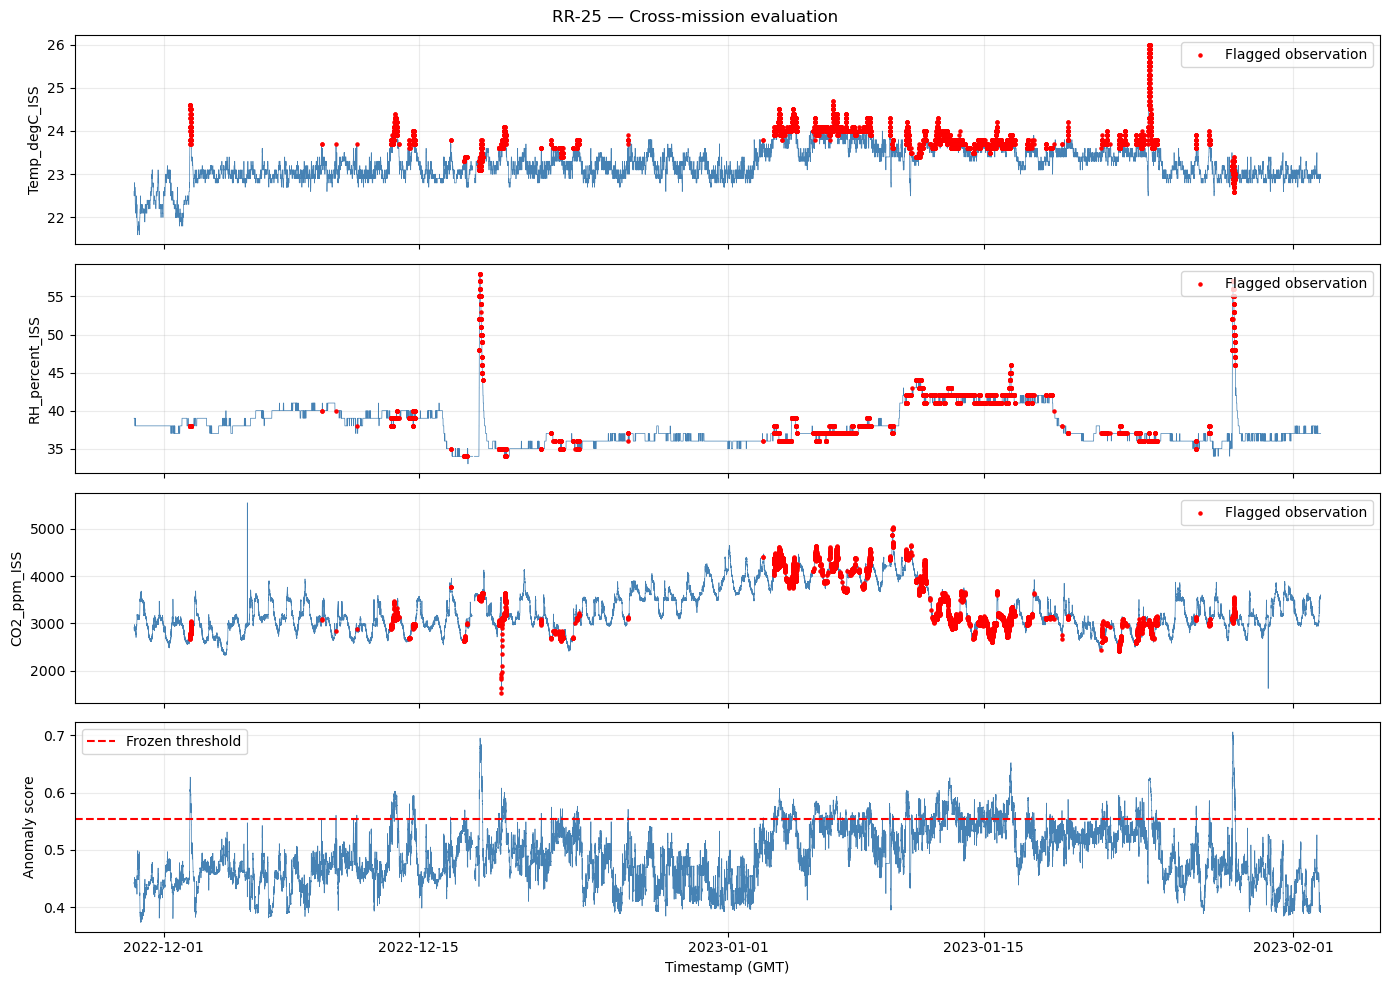

In [14]:
import matplotlib.pyplot as plt

for mission, result in cross_results.items():
    r = result.sort_values("timestamp").copy()

    # တစ်မိနစ်ထက် ပိုကွာရင် plot segment အသစ်ခွဲပါ
    r["segment"] = (
        r["timestamp"].diff() > pd.Timedelta(minutes=1)
    ).cumsum()

    flagged = r.loc[r["is_anomaly"]]

    fig, axes = plt.subplots(
        4, 1, figsize=(14, 10), sharex=True
    )

    for ax, feature in zip(axes[:3], features):
        for _, segment in r.groupby("segment"):
            ax.plot(
                segment["timestamp"],
                segment[feature],
                color="steelblue",
                linewidth=0.5,
            )

        ax.scatter(
            flagged["timestamp"],
            flagged[feature],
            color="red",
            s=5,
            label="Flagged observation",
            zorder=3,
        )
        ax.set_ylabel(feature)
        ax.legend(loc="upper right")
        ax.grid(alpha=0.25)

    for _, segment in r.groupby("segment"):
        axes[3].plot(
            segment["timestamp"],
            segment["anomaly_score"],
            color="steelblue",
            linewidth=0.5,
        )

    axes[3].axhline(
        frozen_threshold,
        color="red",
        linestyle="--",
        label="Frozen threshold",
    )
    axes[3].set_ylabel("Anomaly score")
    axes[3].set_xlabel("Timestamp (GMT)")
    axes[3].legend()
    axes[3].grid(alpha=0.25)

    fig.suptitle(f"{mission} — Cross-mission evaluation")
    plt.tight_layout()

    fig.savefig(
        cross_dir / f"{mission}_evaluation.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()

In [15]:
# မူရင်း features ကို ထိန်းထားပါ
base_features = [
    "Temp_degC_ISS",
    "RH_percent_ISS",
    "CO2_ppm_ISS",
]

# Duplicate timestamps ဖယ်ပြီးသား RR-28 data
timeline = (
    model_data[["timestamp"] + base_features]
    .copy()
    .set_index("timestamp")
    .sort_index()
)

assert timeline.index.is_unique

# Missing minutes ကို explicit NaN rows အဖြစ် ထည့်ပါ
# Sensor values ကို interpolate / forward-fill မလုပ်ပါ
minute_index = pd.date_range(
    start=timeline.index.min(),
    end=timeline.index.max(),
    freq="min",
    name="timestamp",
)

timeline = timeline.reindex(minute_index)

# မူရင်း valid observations တွေကို မှတ်ထားပါ
observed = timeline[base_features].notna().all(axis=1)

time_features = []

for feature in base_features:
    values = timeline[feature]

    # ယခင် 15 မိနစ် — လက်ရှိ observation မပါပါ
    history = values.shift(1).rolling(
        window=15,
        min_periods=15,
    )

    change_name = f"{feature}_change_5min"
    deviation_name = f"{feature}_deviation_past15min"
    std_name = f"{feature}_std_past15min"

    timeline[change_name] = values - values.shift(5)

    timeline[deviation_name] = (
        values - history.median()
    )

    timeline[std_name] = history.std(ddof=0)

    time_features.extend([
        change_name,
        deviation_name,
        std_name,
    ])

features_v2 = base_features + time_features

# ပြည့်စုံတဲ့ past history ရှိတဲ့ original observations ကိုသာ ယူပါ
ready = (
    observed
    & timeline[features_v2].notna().all(axis=1)
)

data_v2 = (
    timeline.loc[ready, features_v2]
    .reset_index()
)

print("Original features:", len(base_features))
print("New time features:", len(time_features))
print("Total features:", len(features_v2))
print("Usable observations:", len(data_v2))
print(
    "Excluded for insufficient history:",
    int(observed.sum() - ready.sum()),
)

display(data_v2.head())

Original features: 3
New time features: 9
Total features: 12
Usable observations: 61100
Excluded for insufficient history: 372


,timestamp,Temp_degC_ISS,RH_percent_ISS,CO2_ppm_ISS,Temp_degC_ISS_change_5min,Temp_degC_ISS_deviation_past15min,Temp_degC_ISS_std_past15min,RH_percent_ISS_change_5min,RH_percent_ISS_deviation_past15min,RH_percent_ISS_std_past15min,CO2_ppm_ISS_change_5min,CO2_ppm_ISS_deviation_past15min,CO2_ppm_ISS_std_past15min
0,2024-03-24 20:32:00,19.9,35.0,476.0,0.0,-0.1,0.138884,2.0,-1.0,1.927578,-20.0,-13.0,8.398413
1,2024-03-24 20:33:00,19.8,34.0,498.0,-0.2,-0.2,0.118134,-1.0,-2.0,1.932184,9.0,9.0,8.883443
2,2024-03-24 20:34:00,19.9,33.0,499.0,-0.3,-0.1,0.126491,-6.0,-2.0,1.995551,16.0,10.0,8.994813
3,2024-03-24 20:35:00,20.0,36.0,480.0,-0.2,0.0,0.128927,-2.0,1.0,2.072036,-25.0,-9.0,8.994813
4,2024-03-24 20:36:00,20.2,39.0,477.0,0.2,0.2,0.125786,3.0,3.0,2.015496,-9.0,-12.0,8.639959


In [16]:
train_cutoff = train_df["timestamp"].max()
val_cutoff = val_df["timestamp"].max()

train_v2 = data_v2.loc[
    data_v2["timestamp"] <= train_cutoff
].copy()

val_v2 = data_v2.loc[
    (data_v2["timestamp"] > train_cutoff)
    & (data_v2["timestamp"] <= val_cutoff)
].copy()

test_v2 = data_v2.loc[
    data_v2["timestamp"] > val_cutoff
].copy()

X_train_v2 = train_v2[features_v2].copy()
X_val_v2 = val_v2[features_v2].copy()
X_test_v2 = test_v2[features_v2].copy()

for name, part in [
    ("Train v2", train_v2),
    ("Validation v2", val_v2),
    ("Test v2", test_v2),
]:
    print(
        f"{name}: {len(part):,} rows | "
        f"{part['timestamp'].min()} → "
        f"{part['timestamp'].max()}"
    )

Train v2: 36,616 rows | 2024-03-24 20:32:00 → 2024-04-19 11:18:00
Validation v2: 12,249 rows | 2024-04-19 11:19:00 → 2024-04-28 00:16:00
Test v2: 12,235 rows | 2024-04-28 00:17:00 → 2024-05-06 13:15:00


v0.2 training completed.
v0.2 provisional threshold: 0.523966


,model,matched_observations,flagged_observations,flagged_percent
0,v0.1 — raw features,12249,123,1.0
1,v0.2 — raw + time features,12249,123,1.0


v0.2 flag,False,True
v0.1 flag,,
False,12003,123
True,123,0


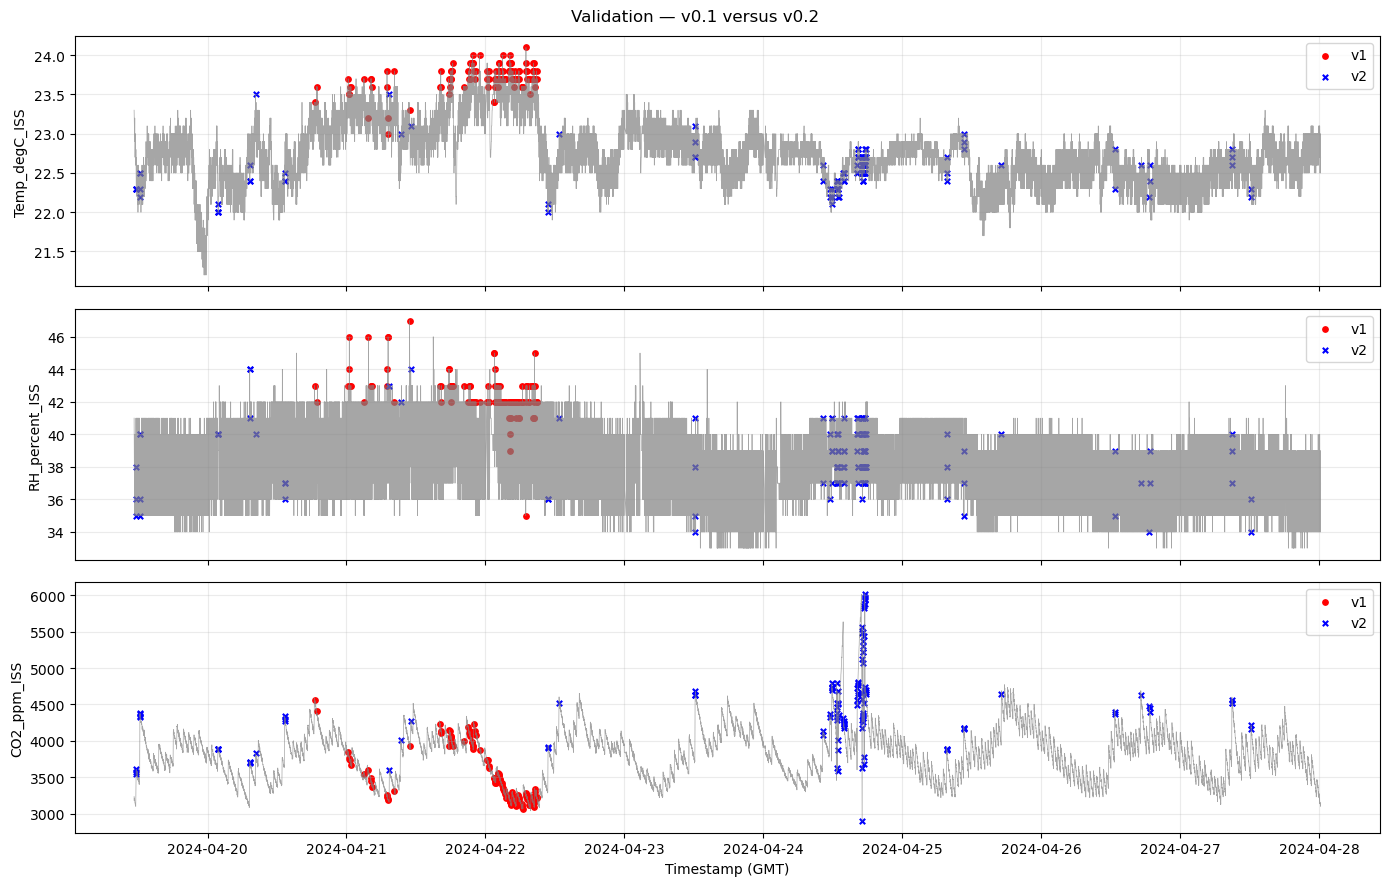

In [17]:
from sklearn.ensemble import IsolationForest

# v0.1 model ကို မပြောင်းဘဲ model အသစ်ဆောက်ပါ
model_v2 = IsolationForest(
    n_estimators=100,
    max_samples="auto",
    contamination="auto",
    random_state=42,
    n_jobs=-1,
)

model_v2.fit(X_train_v2)

train_scores_v2 = -model_v2.score_samples(X_train_v2)
val_scores_v2 = -model_v2.score_samples(X_val_v2)

# v0.2 အတွက် ကိုယ်ပိုင် ယာယီ threshold
threshold_v2 = float(np.percentile(val_scores_v2, 99))

val_results_v2 = val_v2.copy()
val_results_v2["anomaly_score"] = val_scores_v2
val_results_v2["is_anomaly"] = (
    val_scores_v2 > threshold_v2
)

print("v0.2 training completed.")
print(f"v0.2 provisional threshold: {threshold_v2:.6f}")

# v0.2 score တွက်နိုင်တဲ့ timestamps ပေါ်မှာပဲ
# v0.1 နဲ့ နှိုင်းယှဉ်ပါ
comparison = val_results[
    ["timestamp", "anomaly_score", "is_anomaly"]
].merge(
    val_results_v2[
        ["timestamp", "anomaly_score", "is_anomaly"]
    ],
    on="timestamp",
    suffixes=("_v1", "_v2"),
    validate="one_to_one",
)

summary = pd.DataFrame([
    {
        "model": "v0.1 — raw features",
        "matched_observations": len(comparison),
        "flagged_observations":
            int(comparison["is_anomaly_v1"].sum()),
        "flagged_percent":
            100 * comparison["is_anomaly_v1"].mean(),
    },
    {
        "model": "v0.2 — raw + time features",
        "matched_observations": len(comparison),
        "flagged_observations":
            int(comparison["is_anomaly_v2"].sum()),
        "flagged_percent":
            100 * comparison["is_anomaly_v2"].mean(),
    },
])

display(summary.round(2))

# Flag တူ/မတူ စစ်ပါ
display(pd.crosstab(
    comparison["is_anomaly_v1"],
    comparison["is_anomaly_v2"],
    rownames=["v0.1 flag"],
    colnames=["v0.2 flag"],
    dropna=False,
))

# Version နှစ်ခုလုံး flag လုပ်တဲ့အချိန်တွေကို ကြည့်ပါ
fig, axes = plt.subplots(
    3, 1, figsize=(14, 9), sharex=True
)

for ax, feature in zip(axes, base_features):
    ax.plot(
        val_v2["timestamp"],
        val_v2[feature],
        color="gray",
        linewidth=0.5,
        alpha=0.7,
    )

    for version, color, marker in [
        ("v1", "red", "o"),
        ("v2", "blue", "x"),
    ]:
        times = comparison.loc[
            comparison[f"is_anomaly_{version}"],
            "timestamp",
        ]

        points = val_v2.loc[
            val_v2["timestamp"].isin(times)
        ]

        ax.scatter(
            points["timestamp"],
            points[feature],
            color=color,
            marker=marker,
            s=15,
            label=version,
        )

    ax.set_ylabel(feature)
    ax.legend()
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("Timestamp (GMT)")
fig.suptitle("Validation — v0.1 versus v0.2")
plt.tight_layout()
plt.show()

In [18]:
# 1. v0.2 feature calculation — training နဲ့ တူညီရပါမယ်
def make_time_features(raw):
    t = (
        raw[["timestamp"] + base_features]
        .copy()
        .set_index("timestamp")
        .sort_index()
    )

    assert t.index.is_unique

    t = t.reindex(pd.date_range(
        t.index.min(),
        t.index.max(),
        freq="min",
        name="timestamp",
    ))

    for feature in base_features:
        values = t[feature]
        history = values.shift(1).rolling(
            window=15, min_periods=15
        )

        t[f"{feature}_change_5min"] = (
            values - values.shift(5)
        )
        t[f"{feature}_deviation_past15min"] = (
            values - history.median()
        )
        t[f"{feature}_std_past15min"] = (
            history.std(ddof=0)
        )

    return (
        t.dropna(subset=features_v2)
        .reset_index()
    )


# 2. ဆက်တိုက် 240 မိနစ်ကို reference segment အဖြစ် ယူပါ
base_demo = (
    val_df.iloc[:240][["timestamp"] + base_features]
    .reset_index(drop=True)
    .copy()
)

assert len(base_demo) == 240
assert (
    base_demo["timestamp"].diff().iloc[1:]
    == pd.Timedelta(minutes=1)
).all(), "Reference segment မှာ data gap ရှိပါတယ်။"

# ပထမ 60 မိနစ်ကို history အတွက် ချန်ထားပါ
start = 60
stop = 180

scenarios = {}


# 3. Synthetic scenarios ဖန်တီးပါ

# CO2 — တစ်မိနစ် spike
s = base_demo.copy()
s.loc[start, "CO2_ppm_ISS"] += 3000
scenarios["CO2_single_spike"] = (s, start + 1)

# CO2 — 120 မိနစ် ဆက်မြင့်ခြင်း
s = base_demo.copy()
s.loc[start:stop - 1, "CO2_ppm_ISS"] += 3000
scenarios["CO2_sustained_step"] = (s, stop)

# Temperature — 60 မိနစ် ramp + 60 မိနစ် ဆက်မြင့်ခြင်း
s = base_demo.copy()
s.loc[start:119, "Temp_degC_ISS"] += np.linspace(0, 4, 60)
s.loc[120:stop - 1, "Temp_degC_ISS"] += 4
scenarios["Temperature_ramp_and_hold"] = (s, stop)

# Humidity — 120 မိနစ် ဆက်မြင့်ခြင်း
s = base_demo.copy()
s.loc[start:stop - 1, "RH_percent_ISS"] += 20
scenarios["Humidity_sustained_step"] = (s, stop)


# 4. Reference နဲ့ synthetic data နှစ်မျိုးလုံးကို score တွက်ပါ
def score_both(raw):
    prepared = make_time_features(raw)

    prepared["score_v1"] = -model.score_samples(
        prepared[base_features]
    )
    prepared["score_v2"] = -model_v2.score_samples(
        prepared[features_v2]
    )

    prepared["flag_v1"] = (
        prepared["score_v1"] > frozen_threshold
    )
    prepared["flag_v2"] = (
        prepared["score_v2"] > threshold_v2
    )

    return prepared


reference_scores = score_both(base_demo)
reference_flags = reference_scores.set_index("timestamp")

summary_rows = []
scenario_outputs = []

for scenario_name, (raw, injection_stop) in scenarios.items():
    scored = score_both(raw)

    onset = base_demo.loc[start, "timestamp"]
    recovery_start = base_demo.loc[injection_stop, "timestamp"]

    modified = (
        (scored["timestamp"] >= onset)
        & (scored["timestamp"] < recovery_start)
    )
    recovery = scored["timestamp"] >= recovery_start

    scored["scenario"] = scenario_name
    scored["is_synthetic"] = True
    scored["is_modified"] = modified
    scored["is_recovery"] = recovery

    for version in ["v1", "v2"]:
        flag_column = f"flag_{version}"

        reference_for_rows = (
            reference_flags[flag_column]
            .reindex(pd.DatetimeIndex(scored["timestamp"]))
            .to_numpy(dtype=bool)
        )

        flags = scored[flag_column].to_numpy(dtype=bool)
        modified_mask = modified.to_numpy()

        hits = scored.loc[
            modified & scored[flag_column],
            "timestamp",
        ]

        delay = (
            (hits.iloc[0] - onset).total_seconds() / 60
            if not hits.empty
            else np.nan
        )

        summary_rows.append({
            "scenario": scenario_name,
            "model": version,
            "modified_rows": int(modified.sum()),
            "modified_flag_percent":
                round(100 * flags[modified_mask].mean(), 2),
            "reference_flag_percent":
                round(
                    100 * reference_for_rows[modified_mask].mean(),
                    2,
                ),
            "first_flag_delay_min": delay,
            "recovery_flag_percent":
                round(
                    100 * scored.loc[recovery, flag_column].mean(),
                    2,
                ),
        })

    scenario_outputs.append(scored)


# 5. Results ပြပြီး သိမ်းပါ
synthetic_comparison = pd.DataFrame(summary_rows)
display(synthetic_comparison)

synthetic_comparison.to_csv(
    output_dir / "v1_v2_synthetic_comparison.csv",
    index=False,
)

pd.concat(scenario_outputs, ignore_index=True).to_csv(
    output_dir / "v1_v2_synthetic_observations.csv",
    index=False,
)

print("Completed. Models and thresholds unchanged.")

,scenario,model,modified_rows,modified_flag_percent,reference_flag_percent,first_flag_delay_min,recovery_flag_percent
0,CO2_single_spike,v1,1,100.00,0.00,0.0,0.00
1,CO2_single_spike,v2,1,100.00,100.00,0.0,3.35
2,CO2_sustained_step,v1,120,100.00,0.00,0.0,0.00
3,CO2_sustained_step,v2,120,8.33,3.33,0.0,10.00
4,Temperature_ramp_and_hold,v1,120,80.00,0.00,21.0,0.00
5,Temperature_ramp_and_hold,v2,120,13.33,3.33,0.0,11.67
6,Humidity_sustained_step,v1,120,100.00,0.00,0.0,0.00
7,Humidity_sustained_step,v2,120,11.67,3.33,0.0,1.67


Completed. Models and thresholds unchanged.
